In [4]:
import sys
sys.path.append("../src")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import xgboost
from xgboost import XGBRegressor

from features import make_features, FEATURES
from metrics import mae, rmse, coverage, avg_width

print("xgboost version:", xgboost.__version__)

df = pd.read_csv("../data/clean_hourly.csv", index_col=0, parse_dates=True)
df = make_features(df)

train = df.loc[:"2012-06-30"].dropna(subset=FEATURES)
test = df.loc["2012-07-01":]

X_train = train[FEATURES]
y_train = train["cnt"]
X_test = test[FEATURES]
y_test = test["cnt"]

xgboost version: 3.4.1


In [5]:
quantiles = [0.05, 0.5, 0.95]
models = {}

for q in quantiles:
    model = XGBRegressor(
        objective="reg:quantileerror",
        quantile_alpha=q,
        n_estimators=300,
        learning_rate=0.05,
        max_depth=5,
        random_state=42,
    )
    model.fit(X_train, y_train)
    models[q] = model
    print("trained quantile", q)

trained quantile 0.05
trained quantile 0.5
trained quantile 0.95


In [6]:
lower = np.maximum(models[0.05].predict(X_test), 0)
median = np.maximum(models[0.5].predict(X_test), 0)
upper = np.maximum(models[0.95].predict(X_test), 0)

# sometimes the lines cross each other, so we fix that
lower = np.minimum(lower, median)
upper = np.maximum(upper, median)

In [7]:
print("Median MAE:", mae(y_test, median))
print("Median RMSE:", rmse(y_test, median))
print("Coverage (target is 0.90):", coverage(y_test, lower, upper))
print("Average width:", avg_width(lower, upper))

Median MAE: 52.24683397711403
Median RMSE: 85.22772305857534
Coverage (target is 0.90): 0.8571105072463768
Average width: 225.10141


In [8]:
out = test[["cnt"]].copy()
out["lower"] = lower
out["median"] = median
out["upper"] = upper
out.to_csv("../results/quantile_predictions.csv")

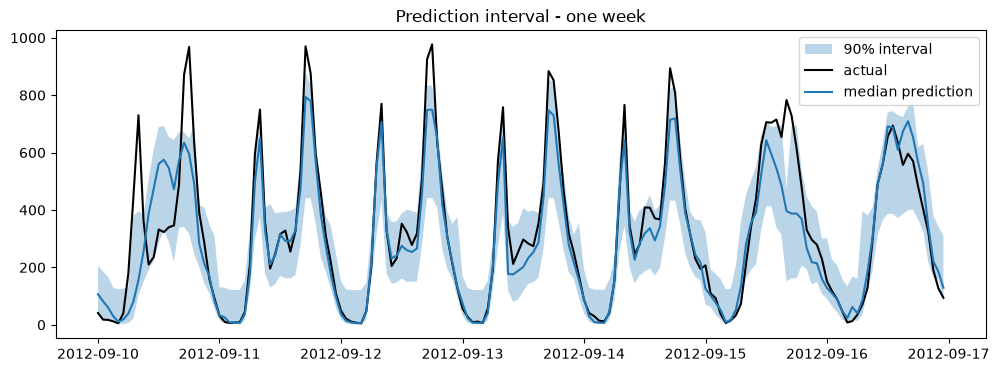

In [9]:
week = out.loc["2012-09-10":"2012-09-16"]

plt.figure(figsize=(12, 4))
plt.fill_between(week.index, week["lower"], week["upper"], alpha=0.3, label="90% interval")
plt.plot(week["cnt"], label="actual", color="black")
plt.plot(week["median"], label="median prediction")
plt.legend()
plt.title("Prediction interval - one week")
plt.savefig("../results/interval_week.png")
plt.show()

In [10]:
out["inside"] = (out["cnt"] >= out["lower"]) & (out["cnt"] <= out["upper"])
print(out["inside"].resample("MS").mean())

datetime
2012-07-01    0.857527
2012-08-01    0.908602
2012-09-01    0.854167
2012-10-01    0.803763
2012-11-01    0.833333
2012-12-01    0.884409
Freq: MS, Name: inside, dtype: float64
